In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.weightstats import ztest

In [25]:
import pandas as pd 
import numpy as np 

df  =  pd.read_csv("hotel_bookings (2).csv")

In [26]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,119380,119381,119382,119383,119384,119385,119386,119387,119388,119389
hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,...,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel,City Hotel
is_canceled,0,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
lead_time,342,737,7,13,14,14,0,9,85,75,...,44,188,135,164,21,23,102,34,109,205
arrival_date_year,2015,2015,2015,2015,2015,2015,2015,2015,2015,2015,...,2017,2017,2017,2017,2017,2017,2017,2017,2017,2017
arrival_date_month,July,July,July,July,July,July,July,July,July,July,...,August,August,August,August,August,August,August,August,August,August
arrival_date_week_number,27,27,27,27,27,27,27,27,27,27,...,35,35,35,35,35,35,35,35,35,35
arrival_date_day_of_month,1,1,1,1,1,1,1,1,1,1,...,31,31,30,31,30,30,31,31,31,29
stays_in_weekend_nights,0,0,0,0,0,0,0,0,0,0,...,1,2,2,2,2,2,2,2,2,2
stays_in_week_nights,0,0,1,1,2,2,2,2,3,3,...,3,3,4,4,5,5,5,5,5,7
adults,2,2,1,1,2,2,2,2,2,2,...,2,2,3,2,2,2,3,2,2,2


In [27]:
print(df.duplicated().sum())

31994


In [28]:
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [29]:
df.shape

(119390, 32)

In [30]:
df["children"] = df["children"].fillna(0)          
df["country"] = df["country"].fillna("Unknown")    
df["has_agent"] = df["agent"].notna()               

df = df.drop(columns=["agent", "company"])

In [31]:
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,0,Transient,0.00,0,0,Check-Out,2015-07-01,False
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,4,No Deposit,0,Transient,0.00,0,0,Check-Out,2015-07-01,False
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,No Deposit,0,Transient,75.00,0,0,Check-Out,2015-07-02,False
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0,No Deposit,0,Transient,75.00,0,0,Check-Out,2015-07-02,True
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,No Deposit,0,Transient,98.00,0,1,Check-Out,2015-07-03,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,0,No Deposit,0,Transient,96.14,0,0,Check-Out,2017-09-06,True
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,0,No Deposit,0,Transient,225.43,0,2,Check-Out,2017-09-07,True
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,0,No Deposit,0,Transient,157.71,0,4,Check-Out,2017-09-07,True
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,0,No Deposit,0,Transient,104.40,0,0,Check-Out,2017-09-07,True


In [33]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df = df[df["total_guests"] > 0]



df["meal"] = df["meal"].replace("Undefined", "SC")  # both labels mean "no meal plan"
df = df[(df["market_segment"] != "Undefined") & (df["distribution_channel"] != "Undefined")]


print("ADR = 0      :", (df.adr == 0).sum())
print("ADR < 0      :", (df.adr < 0).sum())
print("ADR > 1000   :", (df.adr > 1000).sum(), " (largest:", df.adr.max(), ")")

ADR = 0      : 1810
ADR < 0      : 1
ADR > 1000   : 1  (largest: 5400.0 )


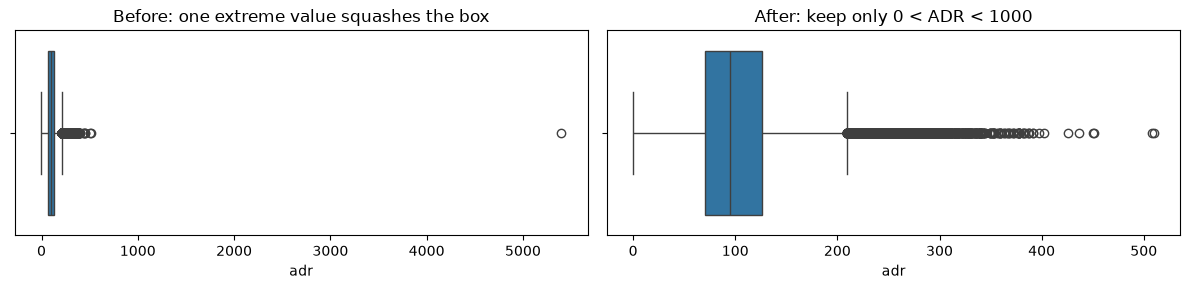

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

sns.boxplot(x=df["adr"], ax=axes[0])
axes[0].set_title("Before: one extreme value squashes the box")

sns.boxplot(x=df[(df.adr > 0) & (df.adr < 1000)]["adr"], ax=axes[1])
axes[1].set_title("After: keep only 0 < ADR < 1000")

plt.tight_layout()
plt.show()

| New column | Built from | Why useful |
|---|---|---|
| `month_num`, `arrival_date`, `arrival_weekday` | year + month + day | Dates let us study seasons and weekdays |
| `season` | month | 12 months is too many for comparing; seasons are how managers plan |
| `total_nights` | weekend + week nights | One "length of stay" number |
| `lead_bucket` | `lead_time` in bands | Turns a skewed number into readable groups |
| `room_mismatch` | reserved room ≠ assigned room |

In [36]:
# Dates
df["month_num"] = pd.to_datetime(df["arrival_date_month"], format="%B").dt.month
df["arrival_date"] = pd.to_datetime(dict(year=df.arrival_date_year, month=df.month_num, day=df.arrival_date_day_of_month))
df["arrival_weekday"] = df["arrival_date"].dt.day_name()

# Season
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month_num"].apply(get_season)
season_order = ["Winter", "Spring", "Summer", "Autumn"]

# Other new columns
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["lead_bucket"] = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 1000],
                           labels=["0-7 days", "8-30", "31-90", "91-180", "180+"])
df["room_mismatch"] = df["reserved_room_type"] != df["assigned_room_type"]

In [38]:
df.head().T

,0,1,2,3,4
hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0,0,0
lead_time,342,737,7,13,14
arrival_date_year,2015,2015,2015,2015,2015
arrival_date_month,July,July,July,July,July
arrival_date_week_number,27,27,27,27,27
arrival_date_day_of_month,1,1,1,1,1
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,0,0,1,1,2
adults,2,2,1,1,2


**Identify the variable types first. The chart follows.**

| You want to show | Variables | Chart | Example here |
|---|---|---|---|
| Shape of **one number** | 1 numeric | **Histogram** or **box plot** | `lead_time`, `adr` |
| Size of **categories** | 1 categorical | **Bar chart** (sorted) | `market_segment` |
| **Number across groups** | numeric + categorical | **Box plot** | `adr` by segment |
| **Two numbers** related? | numeric + numeric | **Scatter plot** | `lead_time` vs `adr` |
| **Many numbers** related? | several numeric | **Correlation heatmap** | numeric columns |
| **Rate across groups** | categorical + yes/no | **Bar chart of percentages** | cancellation % by segment |
| **Two categories → a rate** | categorical + categorical | **Heatmap of rates** | lead time band × hotel |
| **Change over time** | time + numeric | **Line chart** | bookings by month |
| **Two factors → one number** | 2 categorical + numeric | **Interaction (line) plot** | ADR by hotel × season |
| **Observed vs expected** | 1 categorical | **Bars + expected line** | bookings per month |

<Axes: xlabel='lead_time', ylabel='Count'>

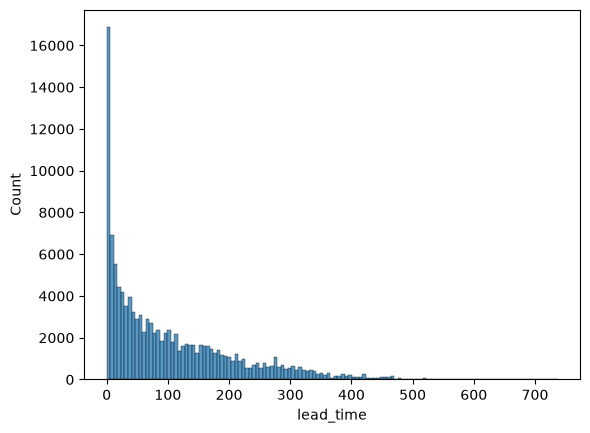

In [39]:
sns.histplot(data=df , x = "lead_time")